# Modularity on the Karate Club Graph
DSC212 research assignment. Recursive spectral modularity partitioning (Newman, 2006, *Modularity and community structure in networks*, PNAS 103(23):8577–8582).

In [1]:
import numpy as np
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

kg = nx.karate_club_graph()
n_nodes, n_edges = kg.number_of_nodes(), kg.number_of_edges()
layout = nx.spring_layout(kg, seed=42)          # fixed layout for every figure
hues = plt.cm.tab10.colors

adj = nx.to_numpy_array(kg, nodelist=range(n_nodes), weight=None)
deg_vec = adj.sum(axis=1)
modmat = adj - np.outer(deg_vec, deg_vec) / (2 * n_edges)     # B = A - kk^T / 2m

## Spectral bipartition and recursive splitting
A community is split by the sign of the leading eigenvector of its block of B, and left alone when the leading eigenvalue is ≤ 0.

In [2]:
def split_two(blk):
    evals, evecs = np.linalg.eigh(blk)
    return evals[-1], np.where(evecs[:, -1] > 0, 1, -1)

def label_vec(prt):
    lbl = np.zeros(n_nodes, dtype=int)
    for j, c in enumerate(sorted(prt, key=lambda c: c[0])):
        lbl[c] = j
    return lbl

def partition_Q(prt):
    lbl = label_vec(prt)
    return float((modmat * (lbl[:, None] == lbl[None, :])).sum()) / (2 * n_edges)

def recursive_split(modmat, tol=1e-10):
    todo, done_groups = [list(range(n_nodes))], []
    snapshots = [[list(range(n_nodes))]]            # iteration 0
    while todo:
        grp = todo.pop(0)
        if len(grp) < 2:
            done_groups.append(grp); continue
        eigval, sv = split_two(modmat[np.ix_(grp, grp)])
        if eigval <= tol or abs(sv.sum()) == len(sv):
            done_groups.append(grp); continue
        todo += [[grp[i] for i in range(len(grp)) if sv[i] == 1],
                 [grp[i] for i in range(len(grp)) if sv[i] == -1]]
        snapshots.append([sorted(c) for c in todo + done_groups])
    return snapshots, [sorted(c) for c in done_groups]

snapshots, final_groups = recursive_split(modmat)
for t, prt in enumerate(snapshots):
    print(f"iteration {t}: {len(prt)} communities, Q = {partition_Q(prt):.4f}")
print("Final communities:", sorted(final_groups, key=lambda c: c[0]))

iteration 0: 1 communities, Q = -0.0000
iteration 1: 2 communities, Q = 0.3715
iteration 2: 3 communities, Q = 0.3898
iteration 3: 4 communities, Q = 0.4081
iteration 4: 5 communities, Q = 0.4094
Final communities: [[0, 1, 2, 3, 7, 12, 13, 17, 19, 21], [4, 5, 6, 10, 16], [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33], [11], [24, 25, 27, 28, 31]]


## Graph after each split

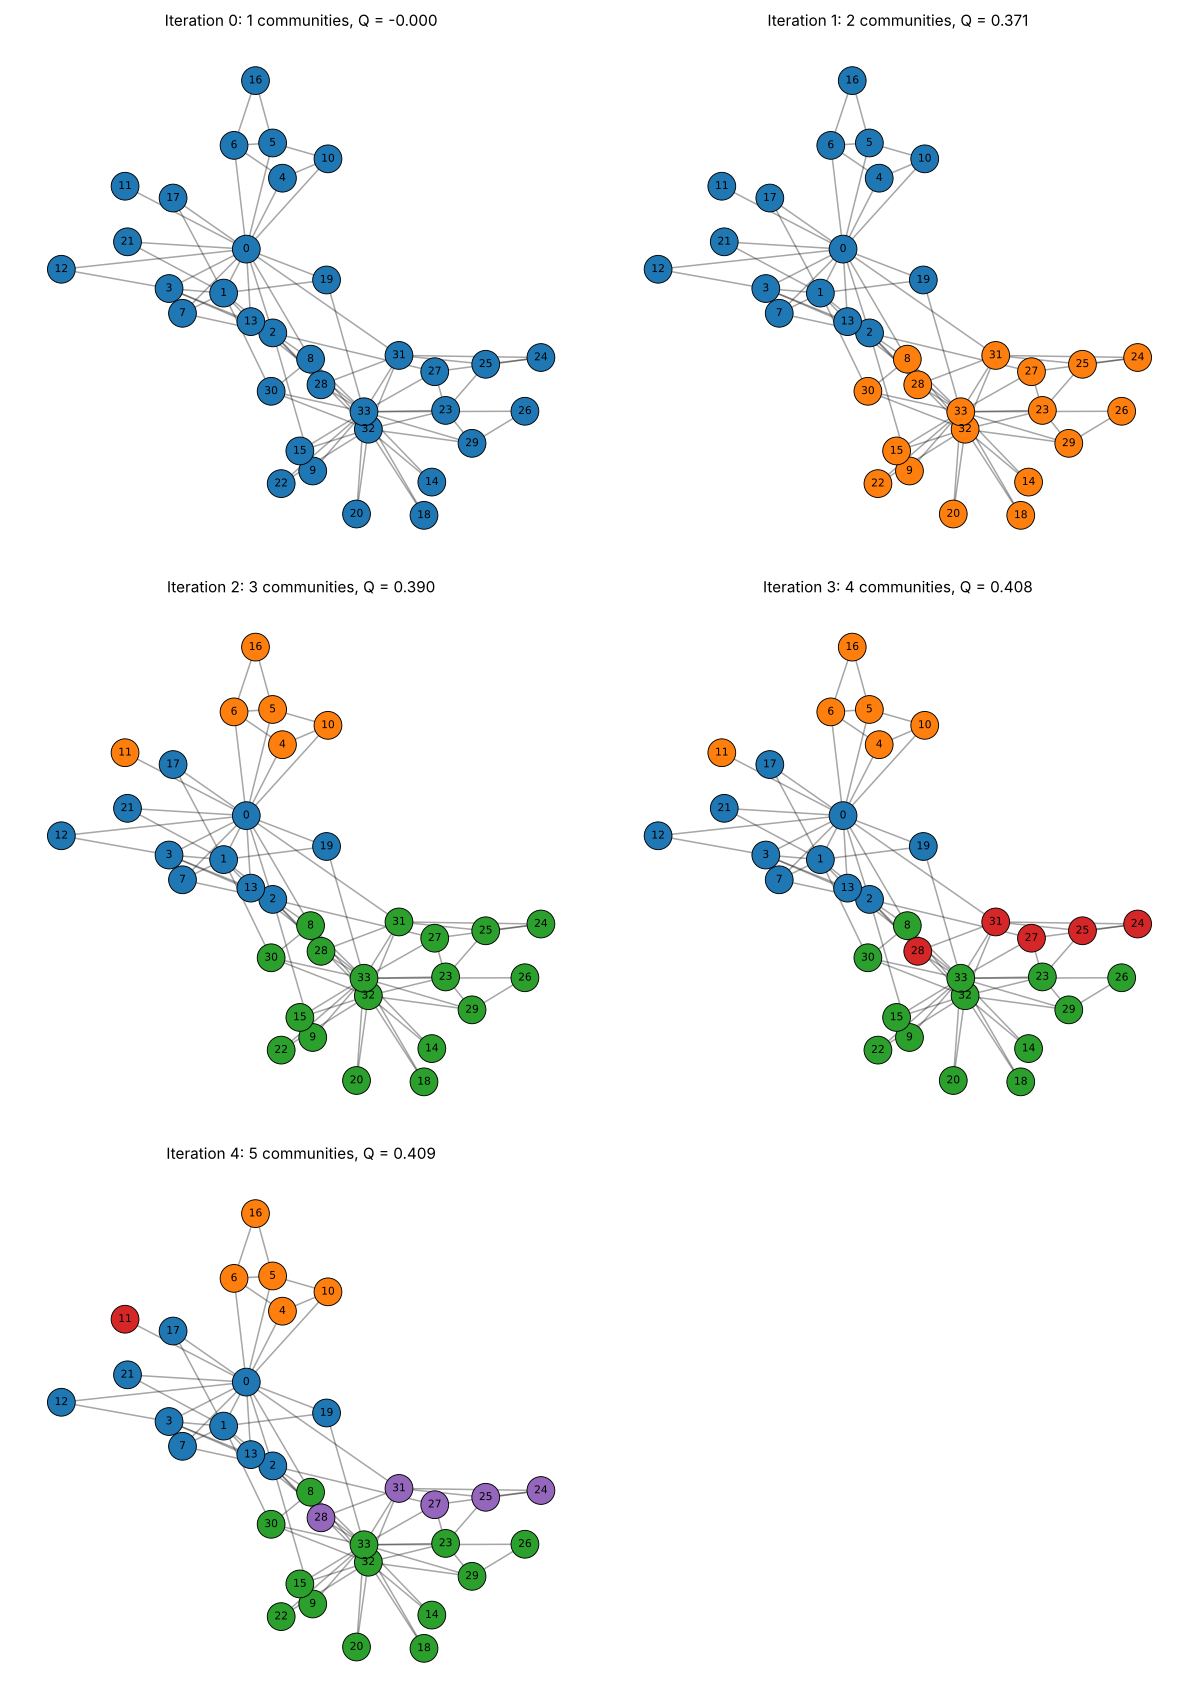

In [3]:
def plot_groups(prt, title, ax):
    lbl = label_vec(prt)
    nx.draw_networkx_edges(kg, layout, ax=ax, alpha=0.35)
    nx.draw_networkx_nodes(kg, layout, ax=ax, node_color=[hues[lbl[v] % 10] for v in kg.nodes()],
                           node_size=330, edgecolors="k", linewidths=0.6)
    nx.draw_networkx_labels(kg, layout, ax=ax, font_size=7)
    ax.set_title(title, fontsize=10); ax.axis("off")

n_snap = len(snapshots)
figure, axs = plt.subplots(int(np.ceil(n_snap / 2)), 2, figsize=(11, 5.2 * int(np.ceil(n_snap / 2))))
axs = axs.ravel()
for t, prt in enumerate(snapshots):
    plot_groups(prt, f"Iteration {t}: {len(prt)} communities, Q = {partition_Q(prt):.3f}", axs[t])
for ax in axs[n_snap:]: ax.axis("off")
plt.tight_layout(); plt.show()

## Node metrics after each split
Metrics are computed inside each node's current community (on the whole graph they would never change). Iteration 0 is the full graph.

In [4]:
def node_metrics(prt):
    res = {"degree": {}, "betweenness": {}, "closeness": {}, "clustering": {}}
    for c in prt:
        if len(c) == 1:
            for key in res: res[key][c[0]] = 0.0
            continue
        sub = kg.subgraph(c)
        res["degree"].update(nx.degree_centrality(sub))
        res["betweenness"].update(nx.betweenness_centrality(sub))
        res["closeness"].update(nx.closeness_centrality(sub))
        res["clustering"].update(nx.clustering(sub))
    return res

metric_log = {t: node_metrics(prt) for t, prt in enumerate(snapshots)}

## Evolution of each metric
Coloured lines are the five nodes with the highest value at iteration 0; the rest are grey.

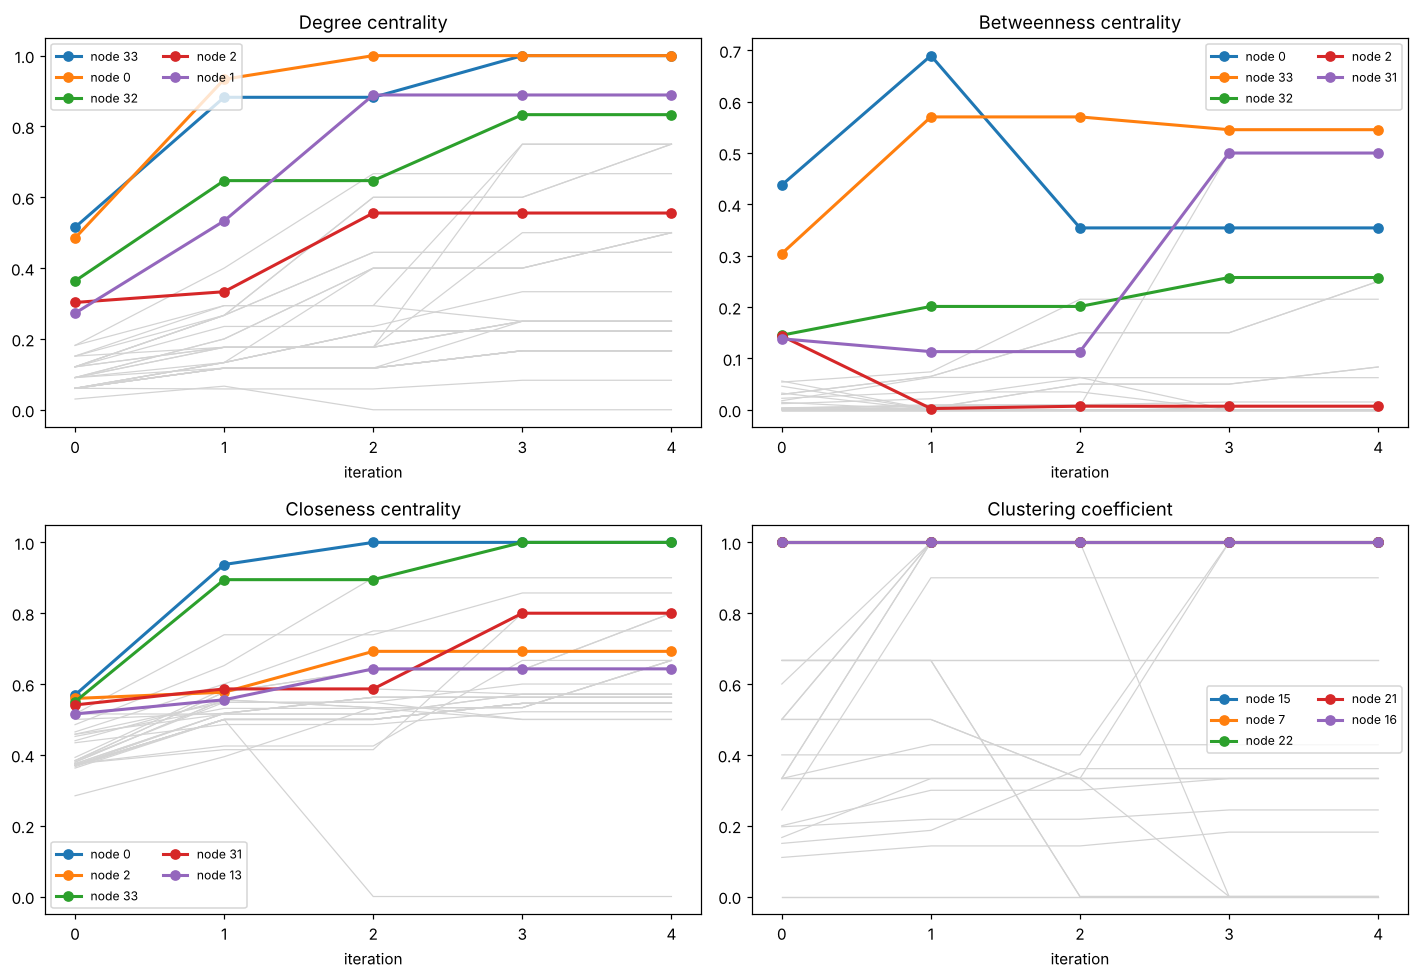

In [5]:
metric_titles = {"degree": "Degree centrality", "betweenness": "Betweenness centrality",
                 "closeness": "Closeness centrality", "clustering": "Clustering coefficient"}
steps = sorted(metric_log)
figure, axs = plt.subplots(2, 2, figsize=(13, 9))
for ax, met in zip(axs.ravel(), metric_titles):
    metric_df = pd.DataFrame({t: metric_log[t][met] for t in steps}).sort_index()
    top5 = metric_df[0].sort_values(ascending=False).head(5).index
    for v in metric_df.index:
        if v not in top5: ax.plot(steps, metric_df.loc[v], color="lightgrey", lw=0.8)
    for j, v in enumerate(top5):
        ax.plot(steps, metric_df.loc[v], marker="o", lw=2, color=hues[j], label=f"node {v}")
    ax.set_title(metric_titles[met]); ax.set_xlabel("iteration"); ax.set_xticks(steps); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

## Discussion
The first cut does most of the work. Splitting on the sign of the leading eigenvector recovers the real club split except for node 8, with Q = 0.37. Going further gives five communities and Q = 0.41, but each extra split adds very little, and the last one just pulls off node 11, which has a single friend. I'd read that as the two factions being the real structure and the rest as fine detail.

Nodes 0 and 33, the instructor and the administrator, stay at or near the top for degree, closeness and betweenness at every step. Their scores go up after the first split mostly because the metrics are now normalised by a smaller group, so the ranking tells us more than the raw values.

Betweenness shows the community effect best. Nodes 2 and 8 look like brokers in the full graph but fall to roughly zero once their communities are separated, since they mainly link groups and do little inside one. Clustering hardly moves for nodes inside tight cliques (15, 16, 21, 22), so it points to the cores of communities and not to the hubs.

One caveat: the metrics are computed inside each node's current community, because on the whole graph they would never change.